In [14]:
import pandas as pd
import numpy as np
import os

# --- 1. CONFIGURATION AND SETTINGS ---

# Column names (C-MAPSS Standard)
index_names = ['unit_nr', 'time_cycles']
setting_names = ['setting_1', 'setting_2', 'setting_3']
sensor_names = ['s_{}'.format(i) for i in range(1, 22)] 
col_names = index_names + setting_names + sensor_names

# Path definitions
raw_path = '../data/raw'
processed_path = '../data/processed'

# Ensure output folder exists
os.makedirs(processed_path, exist_ok=True)

# --- 2. PROCESSING FUNCTION ---

def process_and_save_dataset(file_id):
    print(f"\n{'='*10} Processing {file_id} {'='*10}")
    
    # A. Load Raw Data
    try:
        train_file = os.path.join(raw_path, f'train_{file_id}.txt')
        test_file = os.path.join(raw_path, f'test_{file_id}.txt')
        
        df_train = pd.read_csv(train_file, sep='\s+', header=None, names=col_names)
        df_test = pd.read_csv(test_file, sep='\s+', header=None, names=col_names)
        
        print(f"Data loaded: Train {df_train.shape}, Test {df_test.shape}")

    except FileNotFoundError as e:
        print(f"Error: File not found for {file_id}.")
        return

    # B. Calculate RUL for the TRAINING set
    # Logic: RUL = (Max Cycle of Unit) - (Current Cycle)
    max_cycle = df_train.groupby('unit_nr')['time_cycles'].max().reset_index()
    max_cycle.columns = ['unit_nr', 'max_cycle']
    
    df_train = df_train.merge(max_cycle, on='unit_nr', how='left')
    df_train['RUL'] = df_train['max_cycle'] - df_train['time_cycles']
    
    # Drop auxiliary column 'max_cycle' as it is no longer needed
    df_train.drop('max_cycle', axis=1, inplace=True)

    # C. Remove Constant Sensors (Noise Cleaning)
    # Note: Remove columns with standard deviation = 0 in training.
    # Apply same removal to test set to maintain consistency.
    std_counts = df_train.std(numeric_only=True)
    const_features = std_counts[std_counts == 0].index
    
    if len(const_features) > 0:
        print(f"-> Removing {len(const_features)} constant columns: {list(const_features)}")
        df_train = df_train.drop(const_features, axis=1)
        df_test = df_test.drop(const_features, axis=1, errors='ignore')
    else:
        print("-> No constant columns found.")

    # D. Save processed files
    train_save_path = os.path.join(processed_path, f'train_{file_id}_processed.csv')
    test_save_path = os.path.join(processed_path, f'test_{file_id}_processed.csv')
    
    df_train.to_csv(train_save_path, index=False)
    df_test.to_csv(test_save_path, index=False)
    
    print(f"Success! Files saved in: {processed_path}")

# --- 3. LOOP EXECUTION ---

datasets = ['FD001', 'FD002', 'FD003', 'FD004']

for ds in datasets:
    process_and_save_dataset(ds)

print("\n--- Processing Complete ---")


========== Processing FD001 ==========
Data loaded: Train (20631, 26), Test (13096, 26)
-> Removing 3 constant columns: ['setting_3', 's_18', 's_19']
Success! Files saved in: ../data/processed

========== Processing FD002 ==========
Data loaded: Train (53759, 26), Test (33991, 26)
-> No constant columns found.
Success! Files saved in: ../data/processed

========== Processing FD003 ==========
Data loaded: Train (24720, 26), Test (16596, 26)
-> Removing 3 constant columns: ['setting_3', 's_18', 's_19']
Success! Files saved in: ../data/processed

========== Processing FD004 ==========
Data loaded: Train (61249, 26), Test (41214, 26)
-> No constant columns found.
Success! Files saved in: ../data/processed

--- Processing Complete ---



#################### ANALYZING FD001 ####################
Data Loaded. Shape: (20631, 24)


/opt/anaconda3/lib/python3.11/site-packages/seaborn/matrix.py:260: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  annotation = ("{:" + self.fmt + "}").format(val)


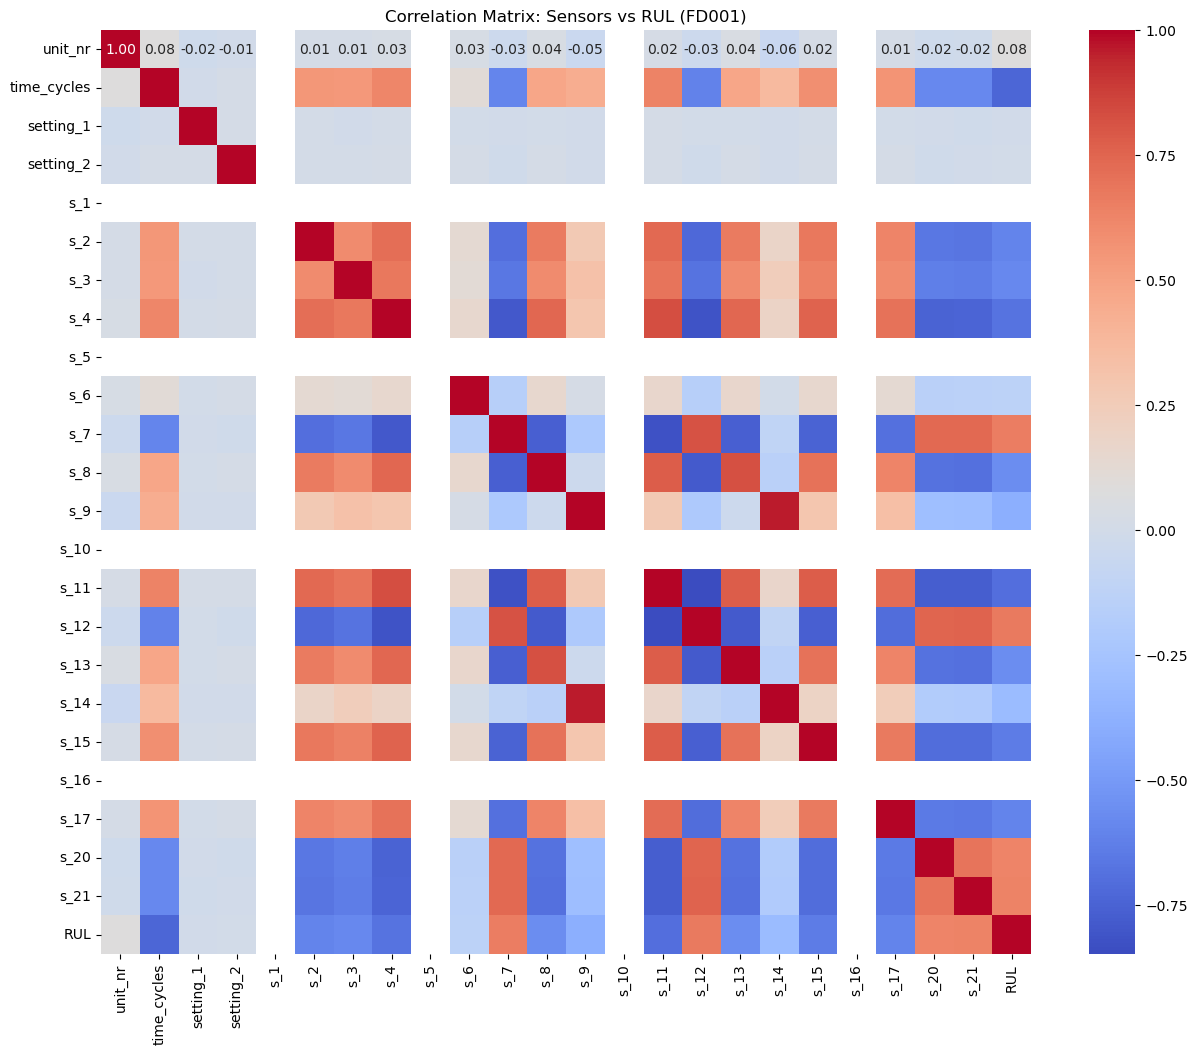


--- Top Sensors most correlated with RUL (FD001) ---
time_cycles    0.736241
s_11           0.696228
s_4            0.678948
s_12           0.671983
s_7            0.657223
s_15           0.642667
s_21           0.635662
s_20           0.629428
s_2            0.606484
s_17           0.606154
Name: RUL, dtype: float64

--------------------------------------------------

#################### ANALYZING FD002 ####################
Data Loaded. Shape: (53759, 27)


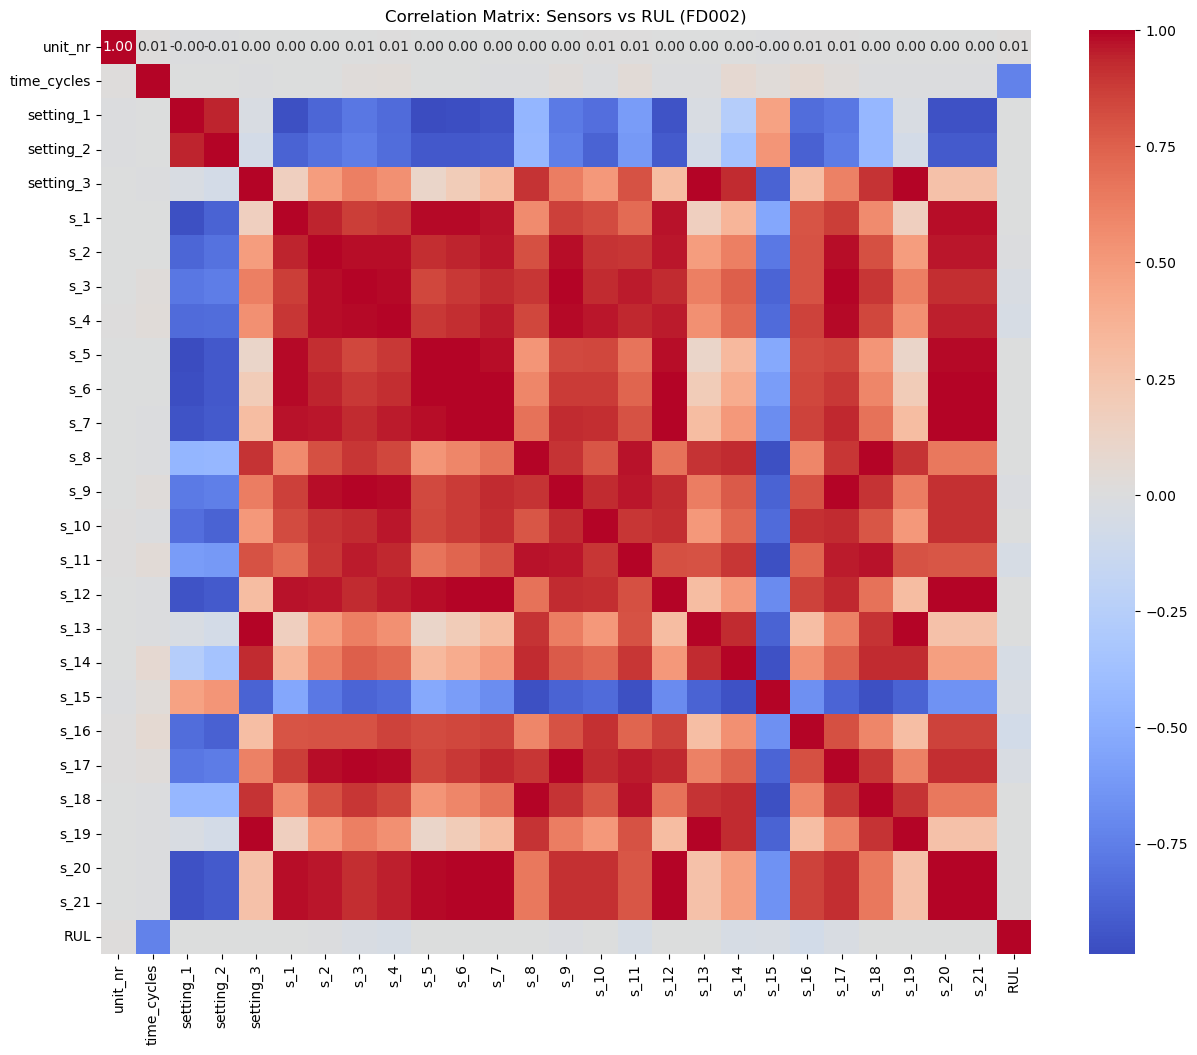


--- Top Sensors most correlated with RUL (FD002) ---
time_cycles    0.733383
s_16           0.071352
s_11           0.046950
s_14           0.042325
s_4            0.040978
s_15           0.038455
s_17           0.027031
s_3            0.026942
s_9            0.015306
unit_nr        0.014608
Name: RUL, dtype: float64

--------------------------------------------------

#################### ANALYZING FD003 ####################
Data Loaded. Shape: (24720, 24)


/opt/anaconda3/lib/python3.11/site-packages/seaborn/matrix.py:260: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  annotation = ("{:" + self.fmt + "}").format(val)


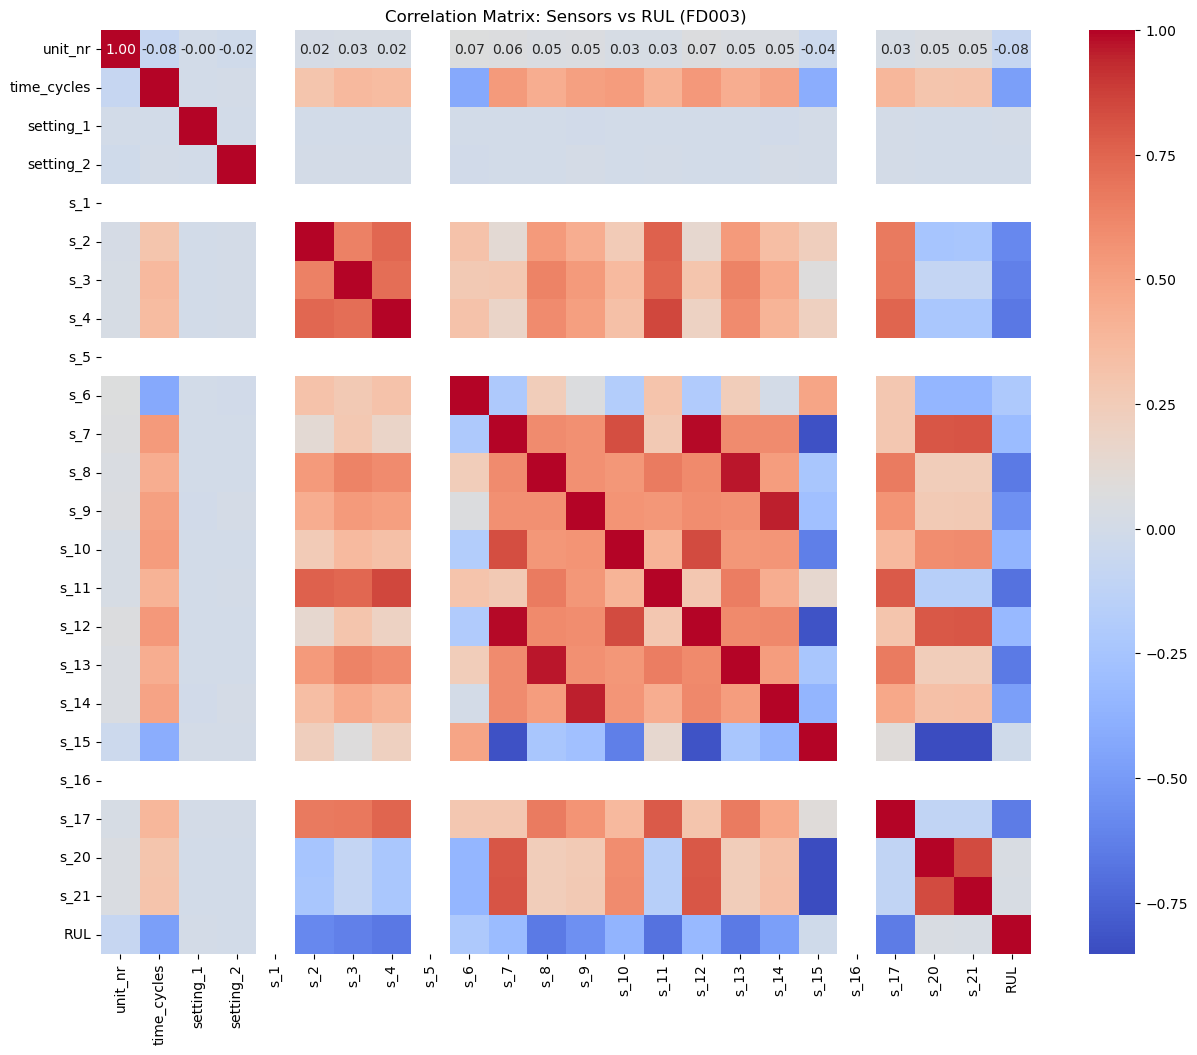


--- Top Sensors most correlated with RUL (FD003) ---
s_11           0.688915
s_4            0.657224
s_13           0.656340
s_8            0.655345
s_17           0.649220
s_3            0.624236
s_2            0.590564
s_9            0.551843
time_cycles    0.482744
s_14           0.481807
Name: RUL, dtype: float64

--------------------------------------------------

#################### ANALYZING FD004 ####################
Data Loaded. Shape: (61249, 27)


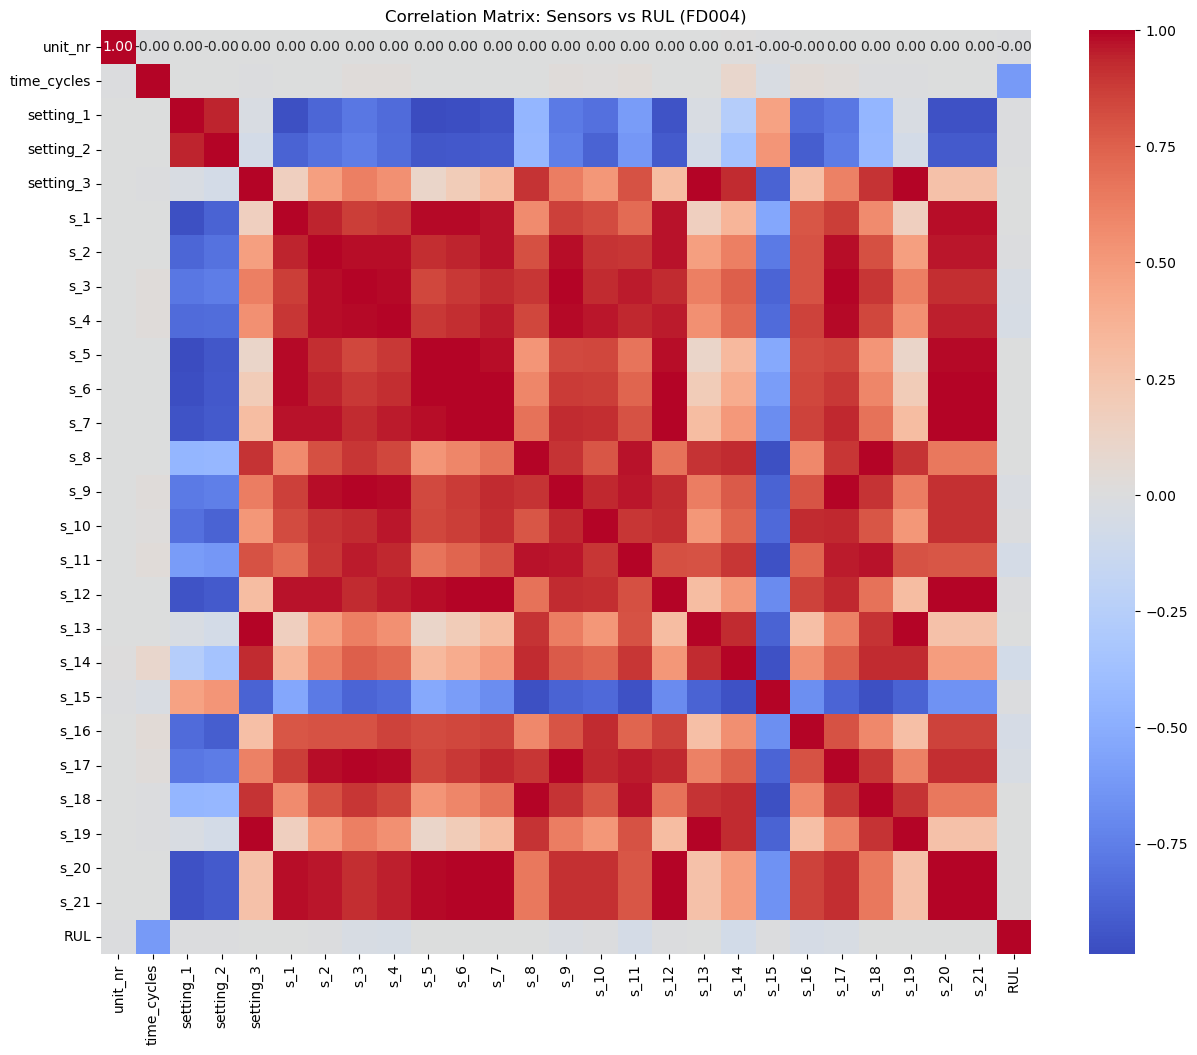


--- Top Sensors most correlated with RUL (FD004) ---
time_cycles    0.610620
s_14           0.078126
s_11           0.056639
s_16           0.053804
s_4            0.045881
s_17           0.032939
s_3            0.032924
s_9            0.024727
s_10           0.008924
s_2            0.004443
Name: RUL, dtype: float64

--------------------------------------------------


In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

# List of datasets to process
dataset_ids = ['FD001', 'FD002', 'FD003', 'FD004']
base_path = '../data/processed'

# Loop through each dataset
for file_id in dataset_ids:
    print(f"\n{'#'*20} ANALYZING {file_id} {'#'*20}")
    
    # 1. Construct file path
    file_path = os.path.join(base_path, f'train_{file_id}_processed.csv')

    # 2. Check if file exists
    if not os.path.exists(file_path):
        print(f"Error: File not found at {file_path}. Please run the processing script first.")
        continue # Skip to the next iteration
    
    # 3. Load Data
    df_train = pd.read_csv(file_path)
    print(f"Data Loaded. Shape: {df_train.shape}")

    # 4. Generate Correlation Matrix
    if not df_train.empty:
        # Calculate correlation (only numeric columns)
        correlation_matrix = df_train.corr(numeric_only=True)

        # Plot Heatmap
        plt.figure(figsize=(15, 12))
        sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
        
        # English Title
        plt.title(f"Correlation Matrix: Sensors vs RUL ({file_id})")
        plt.show()

        # 5. Print Top Correlated Sensors
        # We look at absolute correlation (both positive and negative are important)
        rul_corr = correlation_matrix['RUL'].abs().sort_values(ascending=False)
        
        print(f"\n--- Top Sensors most correlated with RUL ({file_id}) ---")
        # Drop RUL itself (correlation is always 1.0) and show top 10
        print(rul_corr.drop('RUL').head(10))
        
    print("\n" + "-"*50)


==================== PROCESSING FD001 ====================
Top 2 sensors for FD001: ['time_cycles', 's_11']


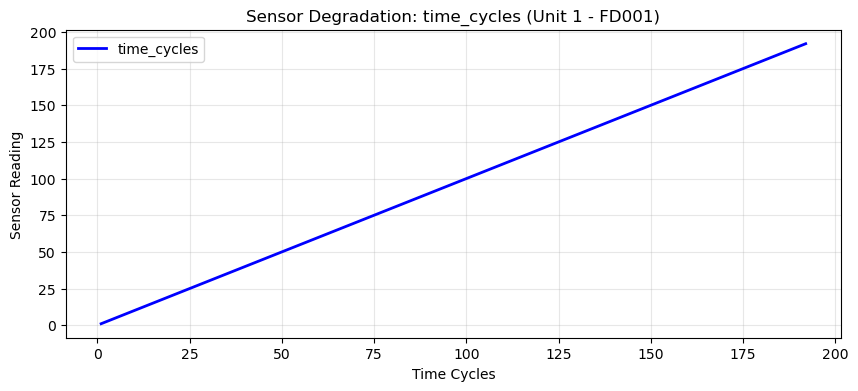

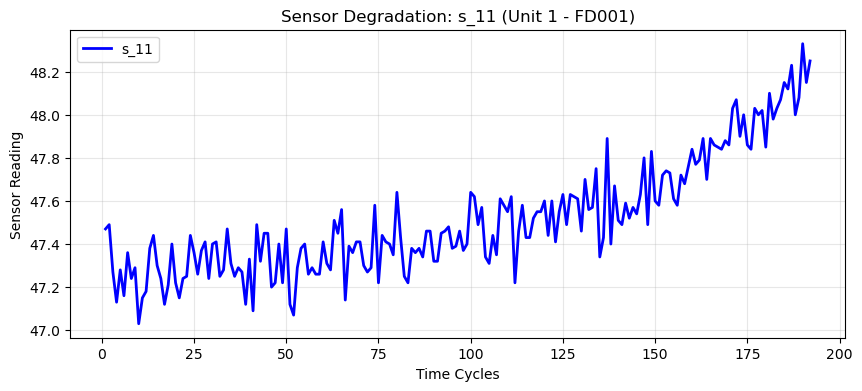


==================== PROCESSING FD002 ====================
Top 2 sensors for FD002: ['time_cycles', 's_16']


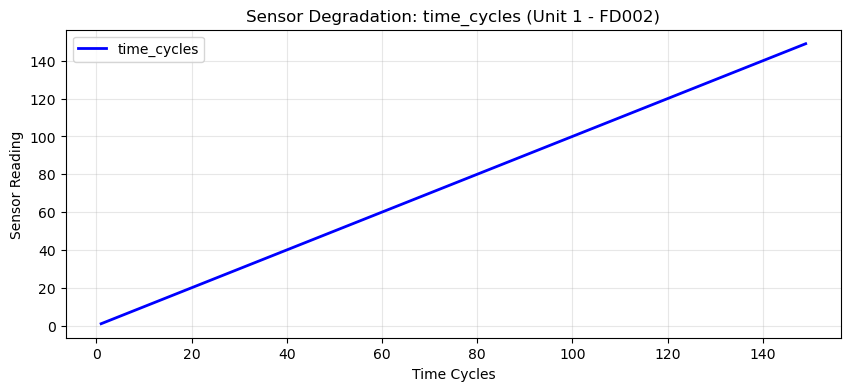

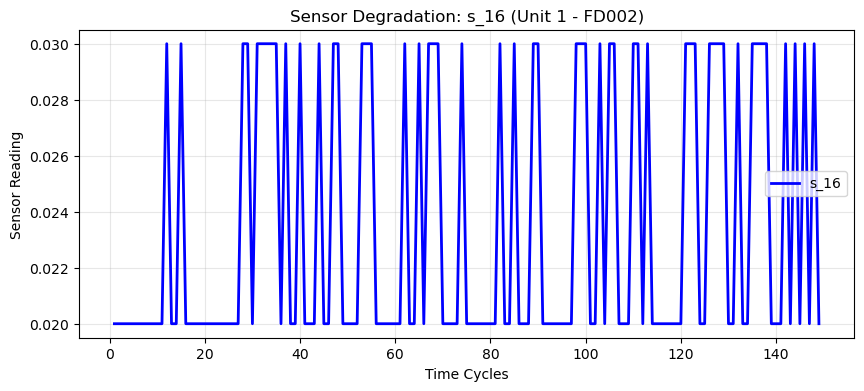


==================== PROCESSING FD003 ====================
Top 2 sensors for FD003: ['s_11', 's_4']


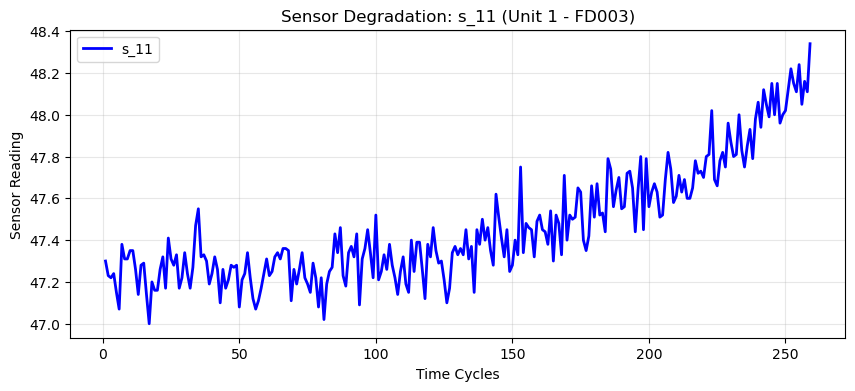

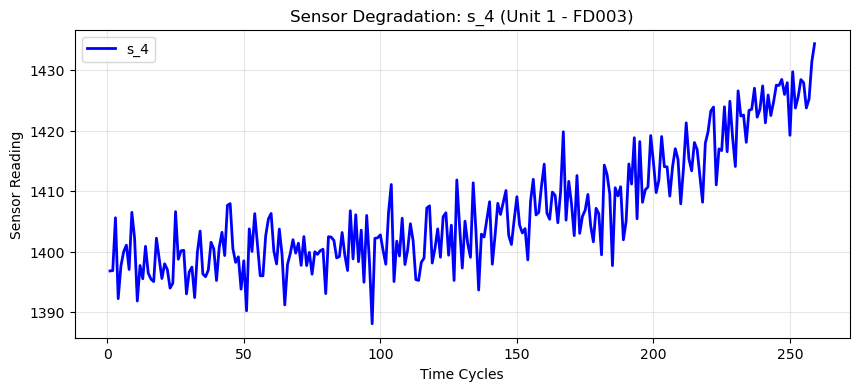


==================== PROCESSING FD004 ====================
Top 2 sensors for FD004: ['time_cycles', 's_14']


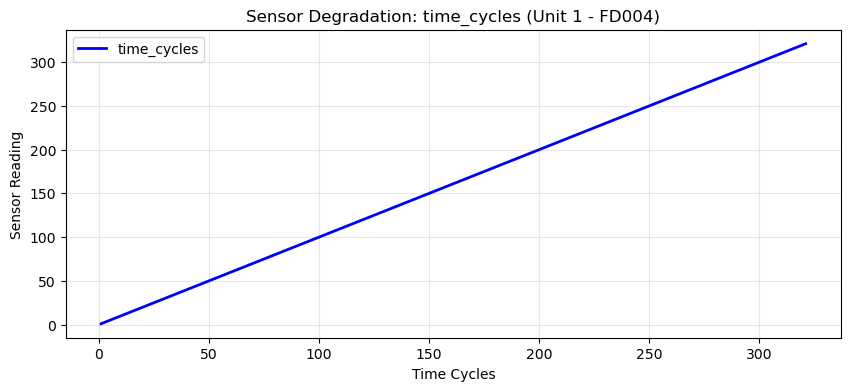

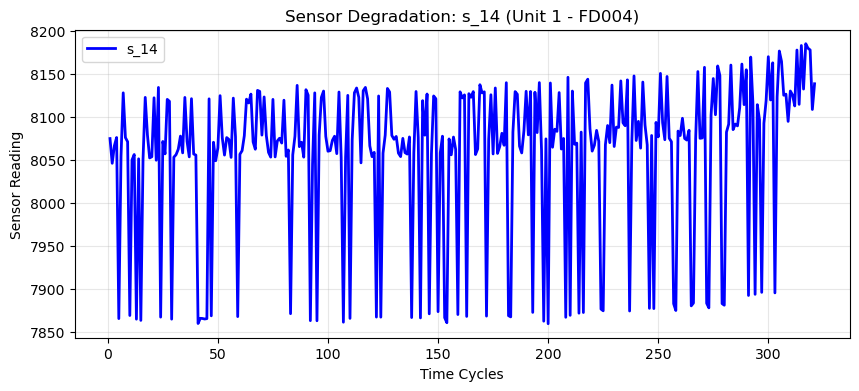

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# --- 1. CONFIGURATION ---
dataset_ids = ['FD001', 'FD002', 'FD003', 'FD004']
base_path = '../data/processed'

# --- 2. PLOTTING FUNCTION (UPDATED) ---
# Now accepts 'df' and 'dataset_name' as arguments so it works inside the loop
def plot_sensor_degradation(df, unit_id, sensor_name, dataset_name):
    # Filter data for the specific unit
    data = df[df['unit_nr'] == unit_id]
    
    plt.figure(figsize=(10, 4))
    # Plot Time vs Sensor Value
    plt.plot(data['time_cycles'], data[sensor_name], label=sensor_name, color='blue', linewidth=2)
    
    # Add titles and labels in English
    plt.title(f'Sensor Degradation: {sensor_name} (Unit {unit_id} - {dataset_name})')
    plt.xlabel('Time Cycles')
    plt.ylabel('Sensor Reading')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

# --- 3. MAIN LOOP ---
for file_id in dataset_ids:
    print(f"\n{'='*20} PROCESSING {file_id} {'='*20}")
    
    # A. Load Data
    file_path = os.path.join(base_path, f'train_{file_id}_processed.csv')
    
    if not os.path.exists(file_path):
        print(f"File not found: {file_path}. Skipping.")
        continue

    df_train = pd.read_csv(file_path)

    # B. Get Top 2 Sensors via Correlation
    # We calculate this again to know WHICH sensors to plot for THIS specific dataset
    if not df_train.empty:
        corr_matrix = df_train.corr(numeric_only=True)
        
        # Get absolute correlation with RUL, sort, remove RUL itself, take top 2
        top_sensors = corr_matrix['RUL'].abs().sort_values(ascending=False).drop('RUL').index[:2]
        
        print(f"Top 2 sensors for {file_id}: {list(top_sensors)}")

        # C. Plot the Top 2 Sensors for Unit 1
        for sensor in top_sensors:
            plot_sensor_degradation(df=df_train, unit_id=1, sensor_name=sensor, dataset_name=file_id)